# 22. Colored local recovery inside scalar V/Phi CLN

This notebook compares the original A-T, condensed A-T, previous scalar V/Phi and optimized scalar V/Phi on identical curved meshes, through all three CLN stages. Physical equations and accuracy gates are unchanged. See [algorithm, measurement and reproduction](BATCHED_SCALAR_CLN.md) and [previous scalar formulation](21_scalar_potential_cln.ipynb).

The optimization groups elements with disjoint **free global coefficients**, then batches their commuting local projections. Shared coefficients are still corrected between colors; boundary coefficients remain fixed. No global curl matrix or vector factorization is introduced. Coloring changes the iterative order, so the measured sweep counts are retained rather than assumed equal.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='docs': root=root.parent
data=json.loads((root/'docs/data/batched_cln_study.json').read_text())
controls=json.loads((root/'docs/data/batched_curl_controls.json').read_text())
assert data['complete'] and controls['complete']
print('Runtime:',data['runtime'])
print(data['timing_protocol'])
routes=['original','condensed','scalar-VPhi','scalar-batched']
labels=[f"p={c['order']}, h={c['maxh']*1000:g} mm" for c in data['cohorts']]
def warm(c,route): return [r for r in c['repeats'] if r['route']==route and r['repeat']>0]
print('cohort | original | condensed | old scalar | colored scalar | scalar speedup')
for label,c in zip(labels,data['cohorts']):
    med=[float(np.median([r['seconds'] for r in warm(c,route)])) for route in routes]
    print(label, ' | '.join(f'{v:.3f}s' for v in med), f'{med[2]/med[3]:.2f}x')
    for route in routes:
        print(' ',route,'raw complete times:',[round(r['seconds'],4) for r in c['repeats'] if r['route']==route])

Runtime: {'host': 'intel11', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'numpy': '2.5.2', 'radia': '5.2.3', 'threads': 4, 'blas_pools': [{'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.34.0.0', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'blas', 'internal_api': 'mkl', 'num_threads': 1, 'prefix': 'mkl_rt', 'version': '2026.1-Product', 'threading_layer': 'intel'}, {'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.30', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'openmp', 'internal_api': 'openmp', 'num_threads': 4, 'prefix': 'libiomp', 'version': None}]}
First observed plus three warmed complete runs per route, alternating order; setup, scalar/local recovery and all residual checks included; mesh and cross-comparison excluded
cohort | original | condensed | old scalar | colored scalar | scalar speedup
p

## Complete timing, including setup and checks

Dots and ranges below show the three warmed observations, with medians as bars. First observations are retained above and in JSON. Timing differences do not establish a general ranking for other geometries, hosts or orders.

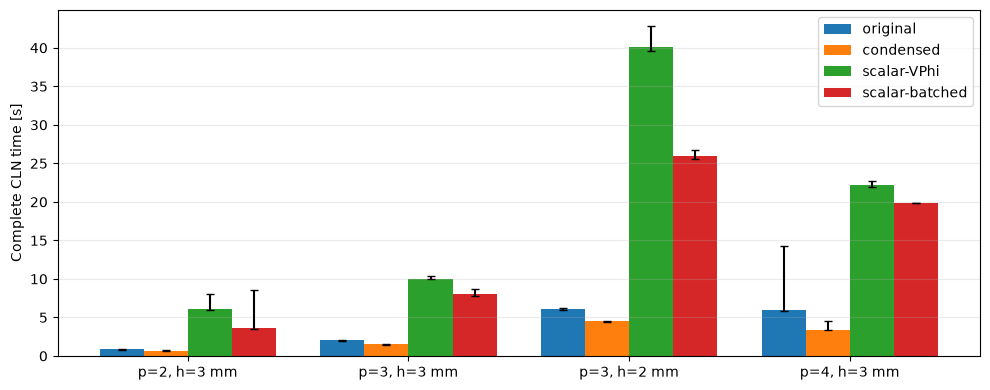

In [2]:
fig,ax=plt.subplots(figsize=(10,4))
x=np.arange(len(labels));width=.2
for j,route in enumerate(routes):
    values=[[r['seconds'] for r in warm(c,route)] for c in data['cohorts']]
    med=np.array([np.median(v) for v in values]);lo=np.array([min(v) for v in values]);hi=np.array([max(v) for v in values])
    pos=x+(j-1.5)*width
    ax.bar(pos,med,width,label=route)
    ax.errorbar(pos,med,yerr=[med-lo,hi-med],fmt='none',color='black',capsize=3)
ax.set_xticks(x,labels);ax.set_ylabel('Complete CLN time [s]');ax.legend();ax.grid(axis='y',alpha=.25)
fig.tight_layout();plt.show()

## Where the time goes

For each run, total time is split into setup, scalar solve, local recovery, and remaining weak residual/energy work. Fast recovery is further split into target assembly, batched projections, algebraic curl checks and integrated physical checks. Median phase values are reported individually; their sum need not equal the median total. The per-stage table covers T0, A1, T1, A2, T2, A3 and T3.

The separate profiler below attributes Python call costs without adding profiling overhead to the matched benchmark. The old projection loop dispatches many small element operations. The colored loop reduces those dispatches; target construction and mandatory physical checks become a greater fraction of the remaining work.

The cProfile records have incomplete coverage of the recovery wall time in this native runtime. Their captured self-time sum is printed explicitly. They are diagnostic call samples, not a complete phase allocation; the engineering phase comparison uses explicit wall clocks and full-run times.

In [3]:
for label,c in zip(labels,data['cohorts']):
    print('\n',label)
    for route in ('scalar-VPhi','scalar-batched'):
        rows=warm(c,route)
        phases=[]
        for r in rows:
            scalar=sum(s['scalar_seconds'] for s in r['solves'])
            recovery=sum(s['recovery_seconds'] for s in r['solves'])
            phases.append([r['setup_seconds'],scalar,recovery,r['seconds']-r['setup_seconds']-scalar-recovery])
        print(route,'setup/scalar/recovery/other [s]:',np.round(np.median(phases,axis=0),4))
    rows=warm(c,'scalar-batched')
    for j in range(7):
        keys=['scalar_seconds','target_seconds','iteration_seconds','curl_check_seconds','field_check_seconds']
        v=np.median([[r['solves'][j][k] for k in keys] for r in rows],axis=0)
        print(rows[0]['solves'][j]['label'],dict(zip(keys,np.round(v,5))))
for p in controls['profiles']:
    print('\nSeparate profile:',p['route'],'sweeps:',p['info']['sweeps'])
    print('Captured self time / recovery wall time:',sum(r['self_seconds'] for r in p['functions']),p['info']['recovery_seconds'])
    for row in p['functions'][:6]:
        print(row['function'], 'calls',row['calls'],'self seconds',round(row['self_seconds'],5))
for p in controls['setup_profiles']:
    print('Separate p=3 construction profile:',p['route'])
    for row in p['construction']: print(row['kind'],row['role'],round(row['seconds'],5),'seconds')
print('Same-color sequential/batch equivalence:',controls['batch_equivalence'])


 p=2, h=3 mm
scalar-VPhi setup/scalar/recovery/other [s]: [0.4495 0.3969 4.5881 0.7477]
scalar-batched setup/scalar/recovery/other [s]: [0.4929 0.412  2.0163 0.7583]
T stage 0 {'scalar_seconds': np.float64(0.04685), 'target_seconds': np.float64(0.09862), 'iteration_seconds': np.float64(0.05916), 'curl_check_seconds': np.float64(0.00365), 'field_check_seconds': np.float64(0.04863)}
A stage 1 {'scalar_seconds': np.float64(0.05931), 'target_seconds': np.float64(0.1047), 'iteration_seconds': np.float64(0.0701), 'curl_check_seconds': np.float64(0.00566), 'field_check_seconds': np.float64(0.06588)}
T stage 1 {'scalar_seconds': np.float64(0.06102), 'target_seconds': np.float64(0.13878), 'iteration_seconds': np.float64(0.06279), 'curl_check_seconds': np.float64(0.00397), 'field_check_seconds': np.float64(0.07231)}
A stage 2 {'scalar_seconds': np.float64(0.0605), 'target_seconds': np.float64(0.13581), 'iteration_seconds': np.float64(0.05669), 'curl_check_seconds': np.float64(0.00482), 'field_c

## Accuracy through the entire recursion

The recovered cumulative potentials feed subsequent scalar stages; this is not postprocessing reference fields. All scalar solves check their original uncondensed equations. The original A-T weak equation is checked both before and after local reconstruction. Coefficients, integrated vector-field differences and energy normalization are checked against the independent A-T route. The curl-fit tolerance remains 1e-10, integrated recovery tolerance 1e-8, and equation/parity gates 1e-6.

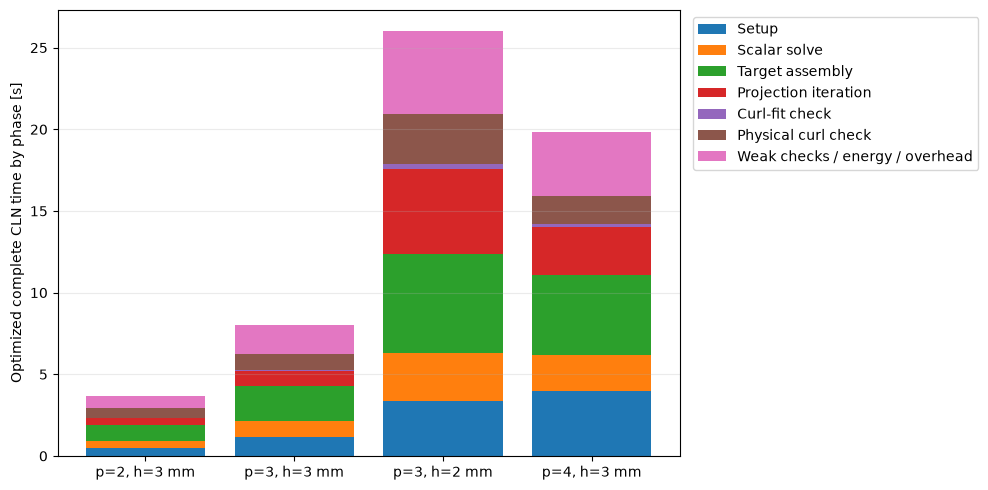

In [4]:
parts=['Setup','Scalar solve','Target assembly','Projection iteration','Curl-fit check','Physical curl check','Weak checks / energy / overhead']
values=[]
for c in data['cohorts']:
    runs=[]
    for r in warm(c,'scalar-batched'):
        v=[r['setup_seconds']]+[sum(s[k] for s in r['solves']) for k in ['scalar_seconds','target_seconds','iteration_seconds','curl_check_seconds','field_check_seconds']]
        runs.append(v+[r['seconds']-sum(v)])
    values.append(np.median(runs,axis=0))
values=np.array(values)
fig,ax=plt.subplots(figsize=(10,5));bottom=np.zeros(len(labels))
for j,name in enumerate(parts):
    ax.bar(labels,values[:,j],bottom=bottom,label=name);bottom+=values[:,j]
ax.set_ylabel('Optimized complete CLN time by phase [s]')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1));ax.grid(axis='y',alpha=.25)
fig.tight_layout();plt.show()

In [5]:
for route in ('scalar-VPhi','scalar-batched'):
    comparisons=[q for c in data['cohorts'] for q in c['comparisons'] if q['route']==route]
    steps=[s for c in data['cohorts'] for r in c['repeats'] if r['route']==route for s in r['solves']]
    print(route,'steps:',len(steps),
          'max coefficient:',max(abs(v) for q in comparisons for v in q['relative_coefficients']),
          'max volume vector field:',max(v for q in comparisons for v in q['volume_relative_field_errors']))
    for key in ('original_scalar_residual','original_physical_residual','recovered_original_residual','relative_curl_field_error'):
        print(key,max(s[key] for s in steps))
    assert all(s['global_vector_solves']==0 and not s['global_matrix_assembled'] for s in steps)
print('Native negative controls:')
for c in controls['cases']: print(c['order'],c['control'],'rejected:',c['rejected'])
assert all(c['rejected'] for c in controls['cases'])
print('Standalone optimized entrypoint:',controls['fast_entrypoint']['route'],len(controls['fast_entrypoint']['solves']),'steps')

scalar-VPhi steps: 112 max coefficient: 1.28620447625849e-10 max volume vector field: 6.505585628680343e-09
original_scalar_residual 1.543820981773974e-14
original_physical_residual 7.40739757412466e-11
recovered_original_residual 4.220549203085412e-10
relative_curl_field_error 8.776964974539681e-11
scalar-batched steps: 112 max coefficient: 1.211699629521945e-10 max volume vector field: 5.350490206885102e-09
original_scalar_residual 1.5200540997406627e-14
original_physical_residual 6.402548448875587e-11
recovered_original_residual 4.1997102762668377e-10
relative_curl_field_error 9.76061254987208e-11
Native negative controls:
2 capped rejected: True
2 incompatible rejected: True
3 capped rejected: True
3 incompatible rejected: True
4 capped rejected: True
4 incompatible rejected: True
Standalone optimized entrypoint: scalar-batched 7 steps


## Engineering conclusion

The table above determines whether the optimized scalar route is faster in each tested cohort. Acceleration of the former scalar implementation does not by itself establish an advantage over A-T. Both comparisons are retained, including raw timing ranges. The simply connected constant-material internal-wire scope, zero shift and three-stage limit remain unchanged. Air, material variation, topology generators and nonlinear or shifted recursions require separate validation.

Reproduce native calculations with the commands in [the implementation note](BATCHED_SCALAR_CLN.md). The portable evidence gate reuses the existing scalar parity checks on both scalar routes, validates phase accounting and negative controls, and rejects five deliberate evidence corruptions.

Measured warmed medians:

| Cohort | Original A-T [s] | Condensed A-T [s] | Old V/Phi [s] | Colored V/Phi [s] | Old/new scalar |
|---|---:|---:|---:|---:|---:|
| p=2, 3 mm | 0.875 | 0.703 | 6.122 | 3.679 | 1.66x |
| p=3, 3 mm | 2.011 | 1.523 | 10.030 | 8.009 | 1.25x |
| p=3, 2 mm | 6.060 | 4.494 | 40.061 | 25.952 | 1.54x |
| p=4, 3 mm | 5.939 | 3.374 | 22.155 | 19.842 | 1.12x |

Maximum optimized coefficient / volume-field / recovered-original-residual errors are 1.212e-10 / 5.350e-09 / 4.200e-10. The optimized scalar implementation remains slower than both A-T references here.